# Supervised Learning and K Nearest Neighbors Exercises

![knn.png](Assets/knn.png)

# Learning Objectives:

- Explicarea învățării supravegheate și modul în care aceasta poate fi aplicată la problemele de regresie și clasificare 
- Aplicarea algoritmului K-Nearest Neighbor (KNN) pentru clasificare
- Aplicați Intel® Extension for Scikit-learn* pentru a valorifica capacitățile de calcul subiacente ale hardware-ului



## Introduction
Pentru exercițiile din prima săptămână, vom utiliza date privind pierderea clienților din industria telecomunicațiilor. Fișierul de date se numește  `Orange_Telecom_Churn_Data.csv`. Vom încărca aceste date împreună, vom efectua o preprocesare și vom utiliza vecinii K-nearest pentru a prezice pierderea clienților pe baza caracteristicilor contului.

In [1]:
from __future__ import print_function
import os
data_path = ['.']

from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

# sklearnex exista doar pentru procesoare x86-64; pe Apple Silicon rulam cu sklearn standard
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    print('sklearnex indisponibil pe aceasta platforma - se foloseste scikit-learn standard')


sklearnex indisponibil pe aceasta platforma - se foloseste scikit-learn standard


## Question 1
* Începeți prin a importa datele. Examinați coloanele și datele.
* Observați că datele conțin un stat, un cod regional și un număr de telefon. Credeți că acestea sunt caracteristici bune de utilizat la construirea unui model de învățare automată? De ce sau de ce nu? 

Nu le vom utiliza, așa că pot fi eliminate din date.

**Raspuns:** Nu sunt caracteristici bune. `phone_number` este un identificator unic pentru fiecare client (nu contine informatie despre comportament, modelul doar l-ar memora). `area_code` are doar 3 valori si e un cod administrativ fara legatura logica cu plecarea clientului, iar `state` are 51 de valori - dupa one-hot ar adauga 51 de coloane rare care domina distanta in KNN si cresc riscul de overfitting. In plus, valorile numerice ale codurilor nu au sens ca distanta (415 nu e "mai aproape" de 408 decat de 510).

In [2]:
import pandas as pd

# Import the data using the file path
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data - Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath)

In [3]:
data.head(1).T

,0
state,KS
account_length,128
area_code,415
phone_number,382-4657
intl_plan,no
voice_mail_plan,yes
number_vmail_messages,25
total_day_minutes,265.1
total_day_calls,110
total_day_charge,45.07


In [4]:
# Remove extraneous columns
data.drop(['state', 'area_code', 'phone_number'], axis=1, inplace=True)

In [5]:
data.columns

Index(['account_length', 'intl_plan', 'voice_mail_plan',
       'number_vmail_messages', 'total_day_minutes', 'total_day_calls',
       'total_day_charge', 'total_eve_minutes', 'total_eve_calls',
       'total_eve_charge', 'total_night_minutes', 'total_night_calls',
       'total_night_charge', 'total_intl_minutes', 'total_intl_calls',
       'total_intl_charge', 'number_customer_service_calls', 'churned'],
      dtype='str')

## Question 2

* Observați că unele dintre coloane sunt date categorice, iar altele sunt date flotante. Aceste caracteristici vor trebui să fie codificate numeric folosind una dintre metodele din curs.
* În cele din urmă, rețineți din prelegere că metoda K-nearest neighbors necesită date scalate. Scalați datele utilizând una dintre metodele de scalare discutate în prelegere.

In [6]:
lb = LabelBinarizer()

for col in ['intl_plan', 'voice_mail_plan', 'churned']:
    data[col] = lb.fit_transform(data[col])
print(data)

      account_length  intl_plan  voice_mail_plan  number_vmail_messages  \
0                128          0                1                     25   
1                107          0                1                     26   
2                137          0                0                      0   
3                 84          1                0                      0   
4                 75          1                0                      0   
...              ...        ...              ...                    ...   
4995              50          0                1                     40   
4996             152          0                0                      0   
4997              61          0                0                      0   
4998             109          0                0                      0   
4999              86          0                1                     34   

      total_day_minutes  total_day_calls  total_day_charge  total_eve_minutes  \
0                 

In [7]:
# Mute the sklearn warning
import warnings
warnings.filterwarnings('ignore', module='sklearn')

msc = MinMaxScaler()

data = pd.DataFrame(msc.fit_transform(data),  # this is an np.array, not a dataframe.
                    columns=data.columns)

## Question 3

Separați coloanele de caracteristici (totul, cu excepția churned) de etichetă (churned). Acest lucru va crea două tabele.
Adaptați un model K-nearest neighbors cu o valoare 'k=3' la aceste date și preziceți rezultatul pe aceleași date.

In [8]:
# Get a list of all the columns that don't contain the label
x_cols = [x for x in data.columns if x != 'churned']

# Split the data into two dataframes
X_data = data[x_cols]
y_data = data['churned']

# # alternatively:
# X_data = data.copy()
# y_data = X_data.pop('churned')

In [9]:
knn = KNeighborsClassifier(n_neighbors=3)

knn = knn.fit(X_data, y_data)

y_pred = knn.predict(X_data)

## Question 4

Metodele de măsurare a erorii nu au fost discutate încă în clasă, dar precizia este ușor de înțeles--este pur și simplu procentul de etichete care au fost prezise corect (fie adevărat, fie fals). 

* Scrieți o funcție pentru a calcula acuratețea folosind etichetele reale și prezise.
* Folosind funcția, calculați precizia acestui model K-nearest neighbors pe date.

In [10]:
# Function to calculate the % of values that were correctly predicted

def accuracy(real, predict):
    return sum(real == predict) / float(real.shape[0])

In [11]:
print(accuracy(y_data, y_pred))

0.9422


## Question 5
* Adaptați din nou modelul K-nearest neighbors cu `n_neighbors=3`, dar de data aceasta utilizați distanța pentru ponderi. Calculați precizia folosind funcția pe care ați creat-o mai sus. 
* Adaptați un alt model K-nearest neighbors. De data aceasta utilizați ponderi uniforme, dar setați parametrul de putere pentru metrica distanței Minkowski la 1 (`p=1`), adică distanța Manhattan.

Atunci când distanțele ponderate sunt utilizate pentru partea 1 a acestei întrebări, pentru acuratețe ar trebui returnată o valoare de 1,0. De ce credeți că este așa? 
* Hint:* facem predicții pe baza datelor, iar cu KNN modelul *este* datele. Vom învăța cum să evităm această capcană în cursul următor.

In [12]:
knn = KNeighborsClassifier(n_neighbors=3, weights='distance')

knn = knn.fit(X_data, y_data)

y_pred = knn.predict(X_data)

print(accuracy(y_data, y_pred))

1.0


In [13]:
knn = KNeighborsClassifier(n_neighbors=3, p=1)

knn = knn.fit(X_data, y_data)

y_pred = knn.predict(X_data)

print(accuracy(y_data, y_pred))

0.9456


**Raspuns:** Evaluam modelul pe aceleasi date pe care l-am antrenat. In KNN modelul *este* setul de date, deci fiecare punct se gaseste pe el insusi ca cel mai apropiat vecin, la distanta 0. Cu `weights='distance'` ponderea este 1/d, adica infinita pentru punctul insusi, asa ca eticheta lui castiga mereu votul -> acuratete 1.0. Este memorare, nu generalizare; acuratetea reala trebuie masurata pe date de test separate.

## Question 6

* Potriviți un model K-nearest neighbors folosind valori ale lui `k` (`n_neighbors`) cuprinse între 1 și 20. Utilizați ponderi uniforme (implicit). Coeficientul pentru distanța Minkowski (`p`) poate fi setat la 1 sau 2 - trebuie doar să fie consecvent. Stocați precizia și valoarea lui `k` utilizată pentru fiecare dintre aceste ajustări într-o listă sau într-un dicționar.
* Reprezentați grafic (sau vizualizați tabelul) `acuratețea` în funcție de `k`. Ce observați că se întâmplă atunci când `k=1`? De ce credeți că este așa? *Hint:* este din același motiv discutat mai sus.

In [14]:
# Fit the K-nearest neighbors model with different values of k
# Store the accuracy measurement for each k

score_list = list()

for k in range(1, 21):
    
    knn = KNeighborsClassifier(n_neighbors=k)
    knn = knn.fit(X_data, y_data)
    
    y_pred = knn.predict(X_data)
    score = accuracy(y_data, y_pred)
    
    score_list.append((k, score))
    
score_df = pd.DataFrame(score_list, columns=['k', 'accuracy'])

In [15]:
# Import libraries to make the plot

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

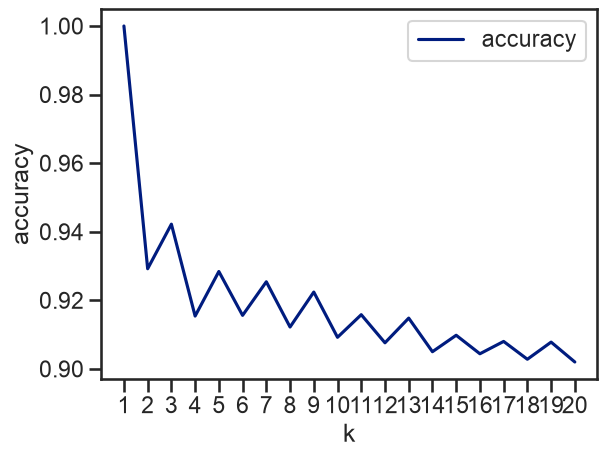

In [16]:
sns.set_context('talk')
sns.set_style('ticks')
sns.set_palette('dark')

ax = score_df.set_index('k').plot()

ax.set(xlabel='k', ylabel='accuracy')
ax.set_xticks(range(1, 21));

**Raspuns:** La `k=1` acuratetea este 1.0, din acelasi motiv: singurul vecin al fiecarui punct este chiar punctul insusi. Pe masura ce k creste, apar si alti vecini in vot, iar acuratetea pe datele de antrenare scade. Graficul nu ne spune ce k e cel mai bun pentru date noi - pentru asta avem nevoie de train/test split sau validare incrucisata.